# EDA Milestone 1: Thống kê dữ liệu cào arXiv

## 1. Cấu hình và đường dẫn

In [1]:
import re, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
DATA = Path("data/eda_input")
if not DATA.exists():
    DATA = Path("notebooks/data/eda_input")
OUT  = DATA.parent / "eda_output"
FIG  = OUT / "figs"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
def normalize_arxiv_id(value):
    value = str(value).strip().replace("_", ".")
    match = re.fullmatch(r"(\d{4})\.(\d{1,5})", value)
    if match:
        return f"{match.group(1)}.{match.group(2).ljust(5, '0')}"
    return value
def save(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=150)
    plt.show()
    plt.close()

## 2. Tổng hợp dữ liệu

In [2]:
def load_all(table):
    files = sorted(DATA.glob(f"{table}*.csv"))
    if not files:
        raise FileNotFoundError(f"Không thấy file {table}*.csv trong {DATA.resolve()}")
    parts = []
    for f in files:
        d = pd.read_csv(f, dtype={"arxiv_id": str})
        if d["arxiv_id"].isna().any():
            raise ValueError(f"{f.name}: có arxiv_id bị thiếu")
        original_ids = d["arxiv_id"].copy()
        d["arxiv_id"] = d["arxiv_id"].map(normalize_arxiv_id)
        if d["arxiv_id"].duplicated().any():
            raise ValueError(f"{f.name}: arxiv_id bị trùng sau chuẩn hóa")
        changed = original_ids.astype(str).ne(d["arxiv_id"])
        if changed.any():
            print(f"{f.name}: đã chuẩn hóa {changed.sum()} arxiv_id bị mất số 0 cuối")
        d["id_range"] = f"{d['arxiv_id'].min()}-{d['arxiv_id'].max()}"
        d["src_file"] = f.name
        parts.append(d)
    return pd.concat(parts, ignore_index=True)
disc = load_all("m1_discovery_stats")
dl   = load_all("m1_download_stats")
ref  = load_all("m1_reference_stats")
for n, d in [("discovery", disc), ("download", dl), ("reference", ref)]:
    print(f"{n:10s}: {len(d):>6} dòng | ID duy nhất {d.arxiv_id.nunique():>6} | {d.id_range.nunique()} dải | cột: {[c for c in d.columns if c not in ('id_range','src_file')]}")

m1_discovery_stats(2412.03848-2412.08847).csv: đã chuẩn hóa 500 arxiv_id bị mất số 0 cuối


m1_download_stats(2412.03848-2412.08847).csv: đã chuẩn hóa 500 arxiv_id bị mất số 0 cuối


discovery :  24999 dòng | ID duy nhất  24999 | 5 dải | cột: ['arxiv_id', 'discovery_status', 'num_versions', 'discovery_time_sec']
download  :  24999 dòng | ID duy nhất  24999 | 5 dải | cột: ['arxiv_id', 'download_status', 'has_tex', 'raw_size_bytes', 'cleaned_size_bytes', 'num_tex_files', 'download_time_sec']
reference :  24999 dòng | ID duy nhất  24999 | 5 dải | cột: ['arxiv_id', 'ref_status', 'num_crawled_refs', 'num_arxiv_refs', 'ref_time_sec']


## 3. Kiểm tra toàn vẹn dữ liệu

In [3]:
def check(cond, msg):
    if not cond:
        raise ValueError("LỖI " + msg)
    print("OK   " + msg)
for n, d in [("discovery", disc), ("download", dl), ("reference", ref)]:
    check(d.arxiv_id.is_unique, f"{n}: không có ID trùng giữa các file/dải")
    check(d.isna().sum().sum() == 0, f"{n}: không có ô trống")
check(set(disc.arxiv_id) == set(dl.arxiv_id), "discovery và download có cùng tập ID")
extra_ref_ids = set(ref.arxiv_id) - set(disc.arxiv_id)
check(not extra_ref_ids, "mọi ID trong reference đều có trong discovery")
missing_ref_ids = sorted(set(disc.arxiv_id) - set(ref.arxiv_id))
print(f"Reference chưa có dòng: {len(missing_ref_ids)} / {len(disc)} bài")
if missing_ref_ids:
    print("Ví dụ ID thiếu:", missing_ref_ids[:10])
check((dl.has_tex == (dl.download_status == "success")).all(), "has_tex == (download_status == 'success')")
check((dl.loc[dl.download_status != "success", "cleaned_size_bytes"] == 0).all(), "bài không có TeX thì cleaned_size_bytes = 0")
check((ref.loc[ref.ref_status != "success", "num_crawled_refs"] == 0).all(), "ref_status != success thì num_crawled_refs = 0")
check((ref.num_arxiv_refs <= ref.num_crawled_refs).all(), "num_arxiv_refs <= num_crawled_refs")
print()
print("discovery_status:", disc.discovery_status.value_counts().to_dict())
print("download_status :", dl.download_status.value_counts().to_dict())
print("ref_status      :", ref.ref_status.value_counts().to_dict())
print("Số dải ID       :", sorted(disc.id_range.unique()), f"({len(disc):,} bài có trong CSV)")
EXPECTED_TOTAL = 24_999
if len(disc) == EXPECTED_TOTAL:
    print(f"OK   đủ {EXPECTED_TOTAL:,} bài như nhóm xác nhận")
else:
    print(f"CẢNH BÁO: có {len(disc):,} bài trong CSV, nhóm xác nhận phải là {EXPECTED_TOTAL:,} (thiếu file hoặc dải?)")

OK   discovery: không có ID trùng giữa các file/dải
OK   discovery: không có ô trống
OK   download: không có ID trùng giữa các file/dải
OK   download: không có ô trống
OK   reference: không có ID trùng giữa các file/dải
OK   reference: không có ô trống


OK   discovery và download có cùng tập ID
OK   mọi ID trong reference đều có trong discovery


Reference chưa có dòng: 0 / 24999 bài
OK   has_tex == (download_status == 'success')
OK   bài không có TeX thì cleaned_size_bytes = 0
OK   ref_status != success thì num_crawled_refs = 0
OK   num_arxiv_refs <= num_crawled_refs

discovery_status: {'success': 24999}
download_status : {'success': 22658, 'pdf_only': 2063, 'failed': 278}
ref_status      : {'success': 24941, 'failed': 37, 'not_found': 21}
Số dải ID       : ['2412.03848-2412.08847', '2412.13848-2412.18847', '2501.07642-2501.12641', '2501.17642-2502.03234', '2502.13235-2502.18234'] (24,999 bài có trong CSV)
OK   đủ 24,999 bài như nhóm xác nhận


## 4. Gộp thành bảng meta

In [4]:
meta = (disc.drop(columns="src_file")
            .merge(dl.drop(columns=["id_range", "src_file"]),  on="arxiv_id", how="inner", validate="one_to_one")
            .merge(ref.drop(columns=["id_range", "src_file"]), on="arxiv_id", how="left", validate="one_to_one"))
meta["ref_status"] = meta["ref_status"].fillna("missing_record")
meta["month"]     = meta["arxiv_id"].str[:4]
meta["num_crawled_refs_valid"] = meta["num_crawled_refs"].where(meta["ref_status"] == "success")
meta["num_arxiv_refs_valid"] = meta["num_arxiv_refs"].where(meta["ref_status"] == "success")
meta["has_ref"]   = (meta["ref_status"] == "success") & (meta["num_crawled_refs"] > 0)
known_ref = meta[meta.ref_status != "missing_record"]
meta["ver_group"] = meta["num_versions"].clip(upper=4).astype(str).replace({"4": "4+"})
tex = meta[meta["has_tex"]]
print(meta.shape)
meta.head()

(24999, 20)


,arxiv_id,discovery_status,num_versions,discovery_time_sec,id_range,download_status,has_tex,raw_size_bytes,cleaned_size_bytes,num_tex_files,download_time_sec,ref_status,num_crawled_refs,num_arxiv_refs,ref_time_sec,month,num_crawled_refs_valid,num_arxiv_refs_valid,has_ref,ver_group
0,2412.03848,success,4,0.0056,2412.03848-2412.08847,success,True,157677639,542151,37,52.263,success,70,53,0.3085,2412,70.0,53.0,True,4+
1,2412.03853,success,2,0.0056,2412.03848-2412.08847,success,True,2824188,64147,2,3.746,success,0,0,0.3085,2412,0.0,0.0,False,2
2,2412.03858,success,1,0.0056,2412.03848-2412.08847,success,True,518331,148306,1,3.645,success,0,0,0.3085,2412,0.0,0.0,False,1
3,2412.03863,success,2,0.0056,2412.03848-2412.08847,success,True,19565,59770,2,5.867,success,5,2,0.3085,2412,5.0,2.0,True,2
4,2412.03868,success,2,0.0056,2412.03848-2412.08847,success,True,25328,91096,2,6.140,success,23,17,0.3085,2412,23.0,17.0,True,2


## 5. Số liệu tổng hợp

In [5]:
n = len(meta)
ok_ref = meta[meta.ref_status == "success"]
summary = {
    "papers_total": n,
    "discovery_success": int((meta.discovery_status == "success").sum()),
    "discovery_success_rate": round(float((meta.discovery_status == "success").mean()), 4),
    "download_tex": int((meta.download_status == "success").sum()),
    "tex_rate": round(float((meta.download_status == "success").mean()), 4),
    "pdf_only": int((meta.download_status == "pdf_only").sum()),
    "pdf_only_rate": round(float((meta.download_status == "pdf_only").mean()), 4),
    "download_failed": int((meta.download_status == "failed").sum()),
    "avg_raw_bytes_tex": round(float(tex.raw_size_bytes.mean()), 1),
    "median_raw_bytes_tex": round(float(tex.raw_size_bytes.median()), 1),
    "avg_cleaned_bytes_tex": round(float(tex.cleaned_size_bytes.mean()), 1),
    "median_cleaned_bytes_tex": round(float(tex.cleaned_size_bytes.median()), 1),
    "avg_crawled_refs_per_successful_paper": round(float(ok_ref.num_crawled_refs.mean()), 2),
    "avg_arxiv_refs_per_successful_paper": round(float(ok_ref.num_arxiv_refs.mean()), 2),
    "ref_success_rate_status": round(float((meta.ref_status == "success").mean()), 4),
    "ref_record_coverage": round(float(len(known_ref) / n), 4),
    "ref_nonempty_rate_successful": round(float(ok_ref.has_ref.mean()), 4),
    "arxiv_ref_nonempty_rate_successful": round(float((ok_ref.num_arxiv_refs > 0).mean()), 4),
    "mean_versions": round(float(meta.num_versions.mean()), 3),
    "total_versions": int(meta.num_versions.sum()),
    "download_hours_sum": round(float(meta.download_time_sec.sum() / 3600), 2),
}
summary_display = pd.DataFrame(
    {"value": [
        f"{value:.2%}" if key.endswith("_rate")
        else f"{value:,.0f}" if float(value).is_integer()
        else f"{value:,.2f}"
        for key, value in summary.items()
    ]},
    index=summary.keys(),
)
summary_display

,value
papers_total,"24,999"
discovery_success,"24,999"
discovery_success_rate,100.00%
download_tex,"22,658"
tex_rate,90.64%
pdf_only,"2,063"
pdf_only_rate,8.25%
download_failed,278
avg_raw_bytes_tex,"7,419,802.80"
median_raw_bytes_tex,"1,903,037.50"


## 6. Tình trạng tải, số phiên bản, số trích dẫn

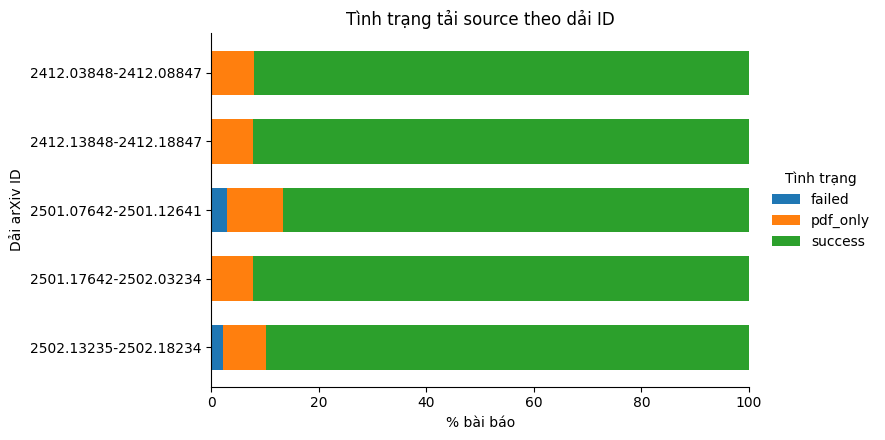

download_status        failed  pdf_only  success
id_range                                        
2412.03848-2412.08847       8       385     4607
2412.13848-2412.18847       2       382     4616
2501.07642-2501.12641     149       516     4335
2501.17642-2502.03234       8       383     4608
2502.13235-2502.18234     111       397     4492


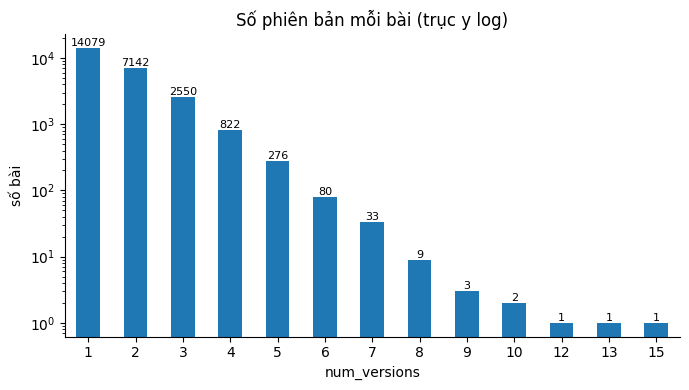

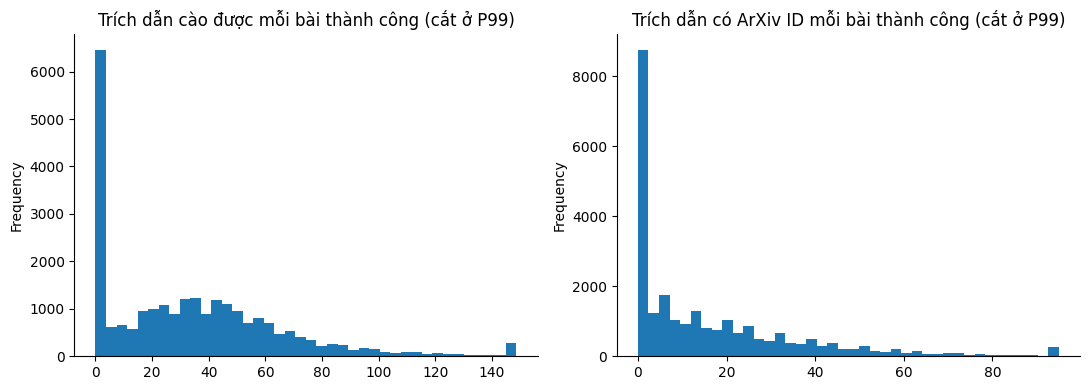

Trong lượt crawl thành công — bài có 0 trích dẫn: 24.4% | bài có 0 trích dẫn ArXiv: 29.4%


In [6]:
st = pd.crosstab(meta.id_range, meta.download_status)
st_pct = st.div(st.sum(axis=1), axis=0).mul(100)
fig, ax = plt.subplots(figsize=(11, 4.5))
st_pct.sort_index(ascending=False).plot(kind="barh", stacked=True, ax=ax, width=0.65)
ax.set(xlim=(0, 100), xlabel="% bài báo", ylabel="Dải arXiv ID",
       title="Tình trạng tải source theo dải ID")
ax.legend(title="Tình trạng", loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
fig.tight_layout(rect=(0, 0, 0.82, 1))
fig.savefig(FIG / "6_1_download_status.png", dpi=150, bbox_inches="tight")
plt.show()
print(st)
v = meta.num_versions.value_counts().sort_index()
ax = v.plot.bar(figsize=(7, 4), rot=0, logy=True, title="Số phiên bản mỗi bài (trục y log)", xlabel="num_versions", ylabel="số bài")
for i, val in enumerate(v.values): ax.text(i, val, str(val), ha="center", va="bottom", fontsize=8)
save("6_2_versions")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
x = ok_ref.num_crawled_refs
x.clip(upper=x.quantile(.99)).plot.hist(bins=40, ax=ax[0], title="Trích dẫn cào được mỗi bài thành công (cắt ở P99)")
y = ok_ref.num_arxiv_refs
y.clip(upper=y.quantile(.99)).plot.hist(bins=40, ax=ax[1], title="Trích dẫn có ArXiv ID mỗi bài thành công (cắt ở P99)")
save("6_3_refs")
print(f"Trong lượt crawl thành công — bài có 0 trích dẫn: {(x == 0).mean():.1%} | bài có 0 trích dẫn ArXiv: {(y == 0).mean():.1%}")

## 7. Kích thước, số file tex, thời gian tải

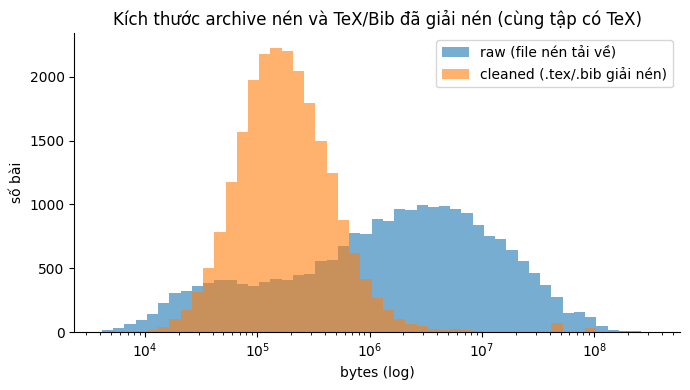

cleaned > raw ở 20.3% số bài có TeX (do raw là file nén)


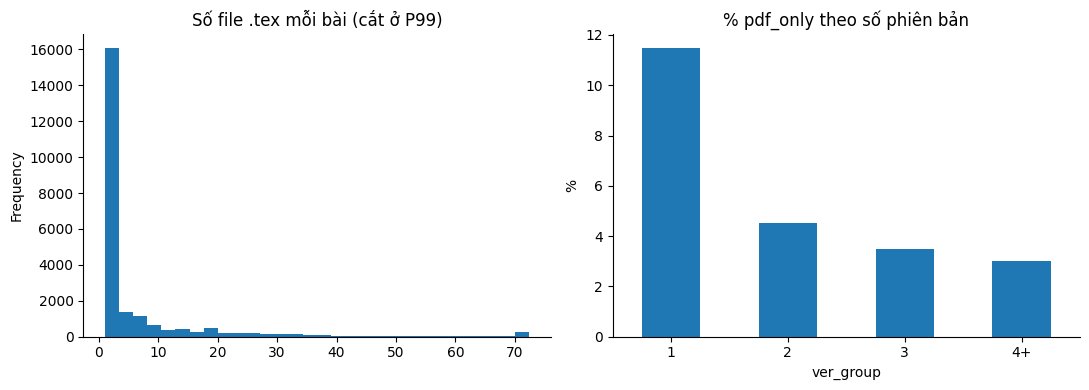

           so_bai  pdf_only  refs_tb_successful
ver_group                                      
1           14079     0.115              26.348
2            7142     0.045              43.588
3            2550     0.035              48.105
4+           1228     0.030              51.764


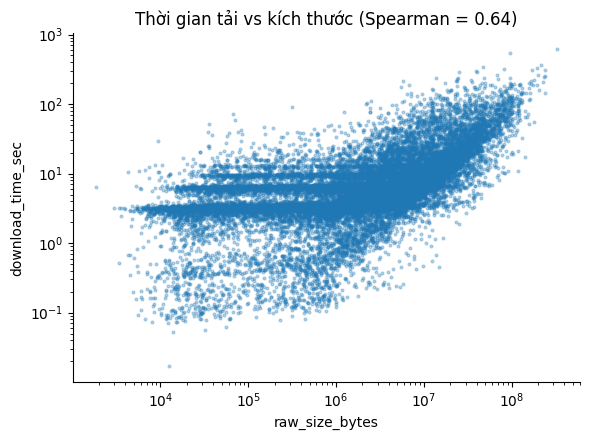

In [7]:
bins = np.logspace(np.log10(max(1, tex.cleaned_size_bytes.min())), np.log10(tex.raw_size_bytes.max()), 50)
plt.figure(figsize=(7, 4))
plt.hist(tex.raw_size_bytes, bins=bins, alpha=.6, label="raw (file nén tải về)")
plt.hist(tex.cleaned_size_bytes, bins=bins, alpha=.6, label="cleaned (.tex/.bib giải nén)")
plt.xscale("log"); plt.xlabel("bytes (log)"); plt.ylabel("số bài"); plt.legend()
plt.title("Kích thước archive nén và TeX/Bib đã giải nén (cùng tập có TeX)")
save("7_1_sizes")
print(f"cleaned > raw ở {(tex.cleaned_size_bytes > tex.raw_size_bytes).mean():.1%} số bài có TeX (do raw là file nén)")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
tex.num_tex_files.clip(upper=tex.num_tex_files.quantile(.99)).plot.hist(bins=30, ax=ax[0], title="Số file .tex mỗi bài (cắt ở P99)")
(meta.groupby("ver_group").download_status.apply(lambda s: (s == "pdf_only").mean() * 100)
     .reindex(["1", "2", "3", "4+"]).plot.bar(ax=ax[1], rot=0, title="% pdf_only theo số phiên bản", ylabel="%"))
save("7_2_texfiles_pdfonly")
print(meta.groupby("ver_group").agg(so_bai=("arxiv_id", "count"), pdf_only=("download_status", lambda s: (s == "pdf_only").mean()),
                                    refs_tb_successful=("num_crawled_refs_valid", "mean")).round(3))
plt.figure(figsize=(6, 4.5))
plt.scatter(tex.raw_size_bytes, tex.download_time_sec, s=4, alpha=.3)
plt.xscale("log"); plt.yscale("log"); plt.xlabel("raw_size_bytes"); plt.ylabel("download_time_sec")
plt.title(f"Thời gian tải vs kích thước (Spearman = {tex[['raw_size_bytes','download_time_sec']].corr(method='spearman').iloc[0,1]:.2f})")
save("7_3_time_vs_size")

## 8. Kiểm tra cột thời gian

In [8]:
print("discovery_time_sec: số giá trị khác nhau =", meta.discovery_time_sec.nunique(), "| tối đa lặp:", meta.discovery_time_sec.value_counts().max())
print("ref_time_sec      : số giá trị khác nhau =", meta.ref_time_sec.nunique(),       "| tối đa lặp:", meta.ref_time_sec.value_counts().max())
print("download_time_sec : số giá trị khác nhau =", meta.download_time_sec.nunique())
print(f"Tổng giờ: discovery {meta.discovery_time_sec.sum()/3600:.2f} h | download {meta.download_time_sec.sum()/3600:.2f} h | reference {meta.ref_time_sec.sum()/3600:.2f} h")

discovery_time_sec: số giá trị khác nhau = 117 | tối đa lặp: 800
ref_time_sec      : số giá trị khác nhau = 1004 | tối đa lặp: 385
download_time_sec : số giá trị khác nhau = 13292
Tổng giờ: discovery 0.41 h | download 81.80 h | reference 3.23 h


## 9. Danh mục, ngày nộp, tác giả 

papers: 24999 dòng | ID duy nhất 24999


phủ 100.0% số bài trong CSV | num_versions khớp len(versions): 100.0%


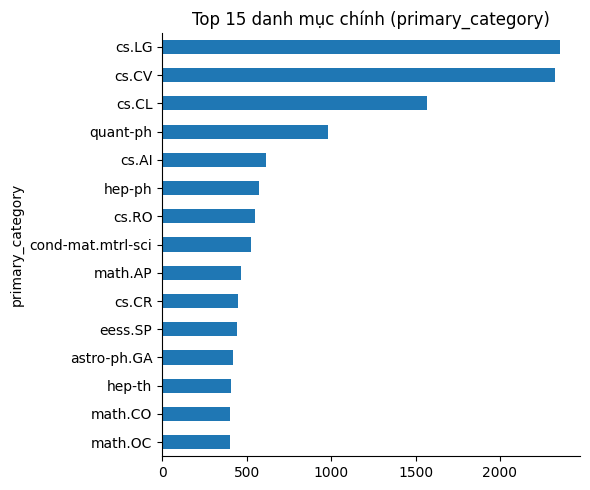

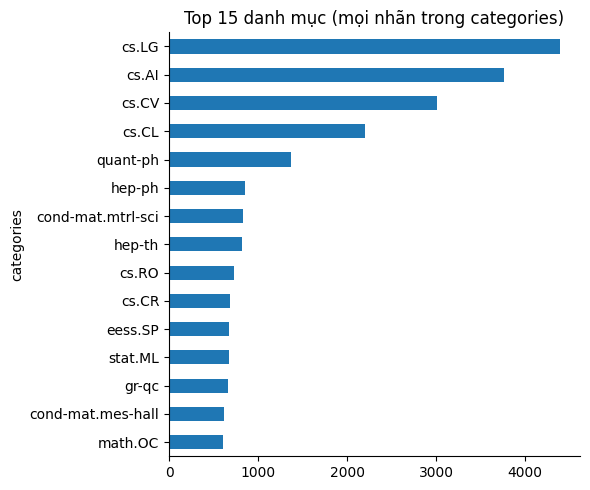

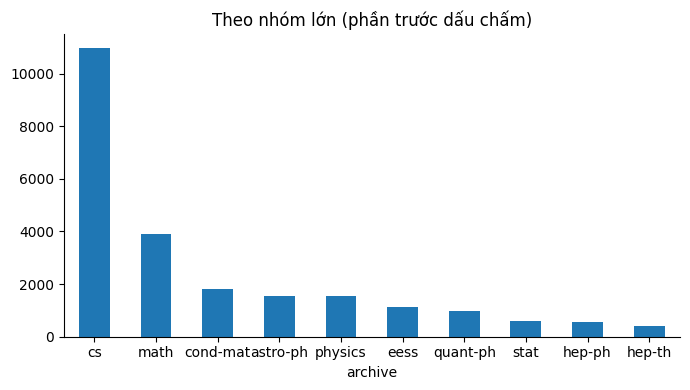

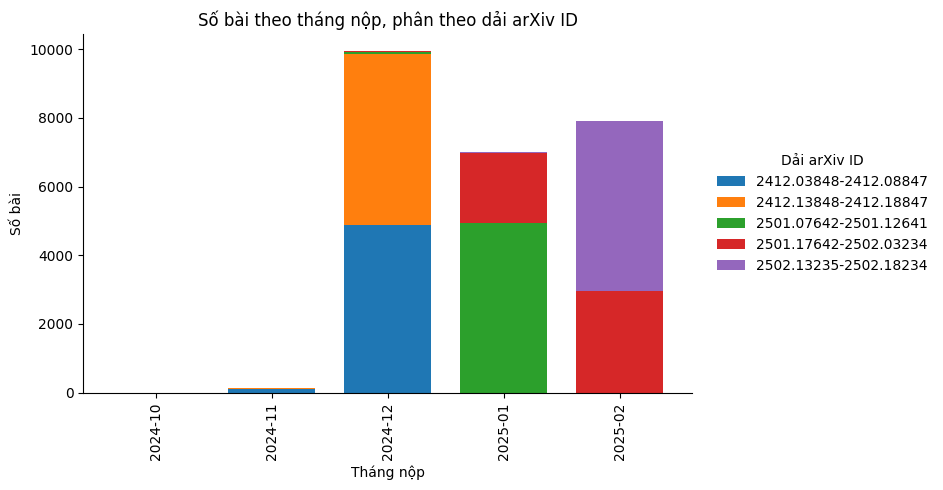

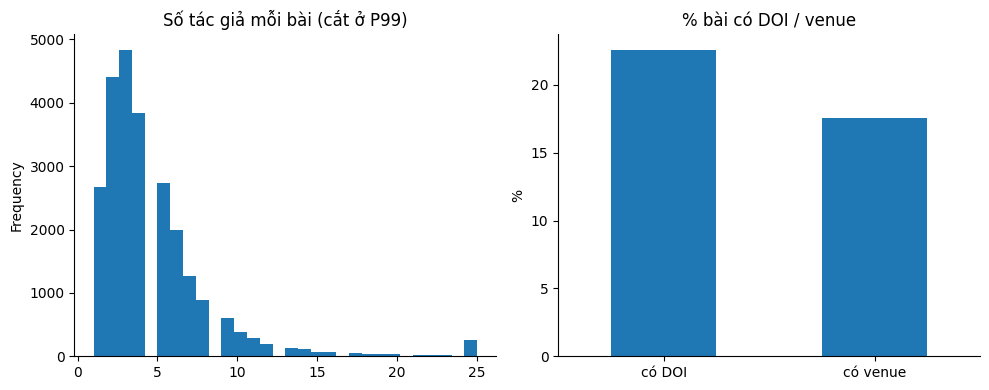

,so_bai,pdf_only,refs_tb_successful,versions_tb
primary_category,,,,
cs.LG,2356,0.052,38.510,1.802
cs.CV,2327,0.043,42.869,1.696
cs.CL,1570,0.060,37.983,1.815
quant-ph,979,0.032,40.628,1.826
cs.AI,617,0.089,35.713,1.703
hep-ph,572,0.003,38.204,1.783
cs.RO,547,0.044,36.463,1.665
cond-mat.mtrl-sci,525,0.440,39.021,1.427
math.AP,469,0.002,23.314,1.561


In [9]:
ID_KEYS = ["arxiv_id", "id", "paper_id"]
KEEP = set(ID_KEYS + ["primary_category", "categories", "authors", "submission_date", "revised_dates", "versions", "doi", "venue"])
def read_papers():
    rows = []
    for f in sorted(DATA.glob("papers*.jsonl")):
        with open(f, encoding="utf-8") as fh:
            for line in fh:
                line = line.strip()
                if not line:
                    continue
                try:
                    r = json.loads(line)
                except json.JSONDecodeError:
                    continue
                rows.append({k: v for k, v in r.items() if k in KEEP})
    for f in sorted(DATA.glob("papers*.parquet")):
        d = pd.read_parquet(f)
        rows += d[[c for c in d.columns if c in KEEP]].to_dict("records")
    return pd.DataFrame(rows)
papers = read_papers()
if papers.empty:
    print("Chưa có papers*.jsonl/parquet trong", DATA.resolve(), "-> bỏ qua phần danh mục.")
else:
    papers["arxiv_id"] = papers["arxiv_id"].map(normalize_arxiv_id)
    print("papers:", len(papers), "dòng | ID duy nhất", papers.arxiv_id.nunique())
    papers = papers.drop_duplicates("arxiv_id")
    papers = papers.dropna(subset=["primary_category", "authors", "versions"])
    papers = papers[papers["arxiv_id"].isin(meta["arxiv_id"])]
    papers = papers.merge(meta[["arxiv_id", "id_range"]], on="arxiv_id", how="left", validate="one_to_one")
    papers["archive"]     = papers["primary_category"].str.split(".").str[0]
    papers["n_authors"]   = papers["authors"].map(len)
    papers["n_versions"]  = papers["versions"].map(len)
    papers["has_doi"]     = papers["doi"].fillna("").ne("")
    papers["has_venue"]   = papers["venue"].fillna("").ne("")
    papers["sub_date"]    = pd.to_datetime(papers["submission_date"], errors="coerce")
    chk = meta[["arxiv_id", "num_versions"]].merge(papers[["arxiv_id", "n_versions"]], on="arxiv_id")
    print(f"phủ {meta.arxiv_id.isin(papers.arxiv_id).mean():.1%} số bài trong CSV | num_versions khớp len(versions): {(chk.num_versions == chk.n_versions).mean():.1%}")
    top = papers["primary_category"].value_counts().head(15)
    top.sort_values().plot.barh(figsize=(6, 5), title="Top 15 danh mục chính (primary_category)")
    save("9_1_top_primary")
    papers["categories"].explode().value_counts().head(15).sort_values().plot.barh(figsize=(6, 5), title="Top 15 danh mục (mọi nhãn trong categories)")
    save("9_2_top_all")
    papers["archive"].value_counts().head(10).plot.bar(figsize=(7, 4), rot=0, title="Theo nhóm lớn (phần trước dấu chấm)")
    save("9_3_archive")
    monthly_by_range = pd.crosstab(papers.sub_date.dt.to_period("M"), papers.id_range)
    monthly_by_range.index = monthly_by_range.index.astype(str)
    fig, ax = plt.subplots(figsize=(12, 5))
    monthly_by_range.plot.bar(stacked=True, ax=ax, width=0.75)
    ax.set(title="Số bài theo tháng nộp, phân theo dải arXiv ID", xlabel="Tháng nộp", ylabel="Số bài")
    ax.legend(title="Dải arXiv ID", loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
    fig.tight_layout(rect=(0, 0, 0.80, 1))
    fig.savefig(FIG / "9_4_submission_by_range.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    papers.n_authors.clip(upper=papers.n_authors.quantile(.99)).plot.hist(bins=30, ax=ax[0], title="Số tác giả mỗi bài (cắt ở P99)")
    pd.Series({"có DOI": papers.has_doi.mean() * 100, "có venue": papers.has_venue.mean() * 100}).plot.bar(ax=ax[1], rot=0, title="% bài có DOI / venue", ylabel="%")
    save("9_5_authors_doi")
    j = meta.merge(papers[["arxiv_id", "primary_category"]], on="arxiv_id", how="inner")
    top10 = j["primary_category"].value_counts().head(10).index
    tab = (j[j["primary_category"].isin(top10)].groupby("primary_category")
             .agg(so_bai=("arxiv_id", "count"),
                  pdf_only=("download_status", lambda s: (s == "pdf_only").mean()),
                  refs_tb_successful=("num_crawled_refs_valid", "mean"),
                  versions_tb=("num_versions", "mean")).round(3).sort_values("so_bai", ascending=False))
    tab.to_csv(OUT / "category_vs_quality_top10.csv")
    top.rename_axis("primary_category").rename("papers").reset_index().to_csv(OUT / "category_top15.csv", index=False)
    display(tab)

## 10. Benchmark pipeline

peak_disk_mb: tăng đều qua các batch = False
final_storage_mb: tăng đều qua các batch = False


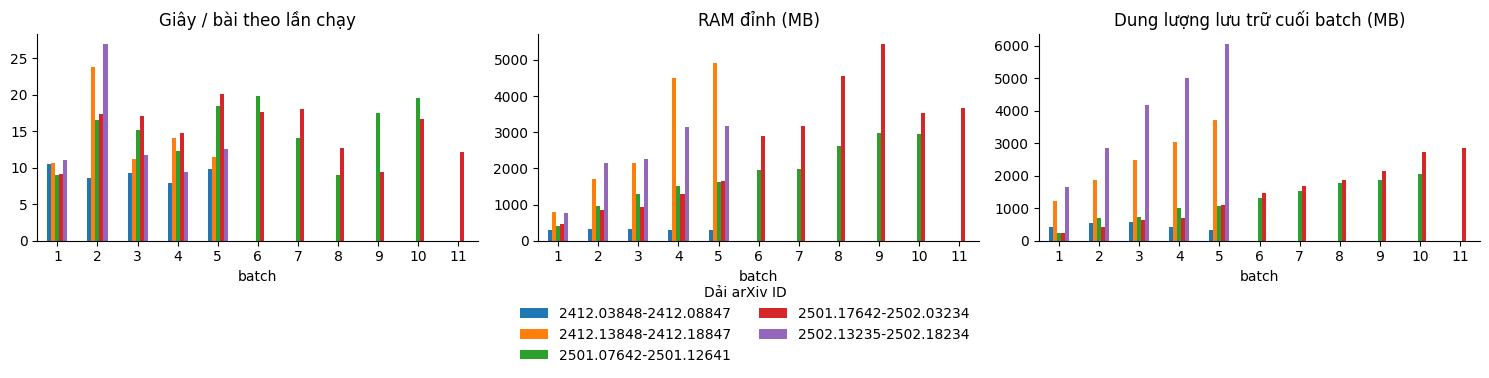

Tổng 24999 bài | tổng thời gian 94.6 h | TB 13.6 s/bài | RAM đỉnh cao nhất 5450 MB


,total_papers,total_wall_time_sec,peak_ram_mb,average_ram_mb,peak_disk_mb,final_storage_mb,src_file,member,batch,sec_per_paper
0,1000.0,10496.66,298.57,241.22,598.48,425.74,m1_version_pipeline_benchmark(2412.03848-2412....,2412.03848-2412.08847,1,10.50
1,1000.0,8599.73,324.03,248.09,782.82,552.35,m1_version_pipeline_benchmark(2412.03848-2412....,2412.03848-2412.08847,2,8.60
2,1000.0,9243.06,335.64,242.78,707.15,570.94,m1_version_pipeline_benchmark(2412.03848-2412....,2412.03848-2412.08847,3,9.24
3,1000.0,7928.78,294.10,236.41,537.45,425.02,m1_version_pipeline_benchmark(2412.03848-2412....,2412.03848-2412.08847,4,7.93
4,1000.0,9758.16,299.34,238.54,471.26,327.17,m1_version_pipeline_benchmark(2412.03848-2412....,2412.03848-2412.08847,5,9.76
5,1000.0,10706.78,793.31,257.98,1361.03,1205.33,m1_version_pipeline_benchmark(2412.13848-2412....,2412.13848-2412.18847,1,10.71
6,1000.0,23792.95,1705.86,280.16,2047.71,1878.01,m1_version_pipeline_benchmark(2412.13848-2412....,2412.13848-2412.18847,2,23.79
7,1000.0,11236.78,2151.12,266.82,2680.13,2475.32,m1_version_pipeline_benchmark(2412.13848-2412....,2412.13848-2412.18847,3,11.24
8,1000.0,14120.97,4494.12,524.20,3267.73,3040.23,m1_version_pipeline_benchmark(2412.13848-2412....,2412.13848-2412.18847,4,14.12
9,1000.0,11432.16,4904.54,1708.96,3933.38,3705.88,m1_version_pipeline_benchmark(2412.13848-2412....,2412.13848-2412.18847,5,11.43


In [10]:
bench = pd.concat([pd.read_csv(f).assign(src_file=f.name) for f in sorted(DATA.glob("m1_version_pipeline_benchmark*.csv"))], ignore_index=True)
rng = bench["src_file"].str.extract(r"(\d{4}[._]\d{5}-\d{4}[._]\d{5})")[0].str.replace("_", ".", regex=False)
bench["member"] = rng.fillna(bench["src_file"])
bench["batch"] = bench.groupby("member").cumcount() + 1
bench["sec_per_paper"] = bench.total_wall_time_sec / bench.total_papers
for col in ["peak_disk_mb", "final_storage_mb"]:
    mono = bench.groupby("member")[col].apply(lambda s: s.is_monotonic_increasing).all()
    print(f"{col}: tăng đều qua các batch = {mono}")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, (col, title) in zip(ax, [("sec_per_paper", "Giây / bài theo lần chạy"), ("peak_ram_mb", "RAM đỉnh (MB)"), ("final_storage_mb", "Dung lượng lưu trữ cuối batch (MB)")]):
    plot = bench.pivot(index="batch", columns="member", values=col).plot.bar(ax=a, rot=0, title=title, legend=(col == "sec_per_paper"))
    if col == "sec_per_paper":
        legend_handles, legend_labels = plot.get_legend_handles_labels()
        plot.get_legend().remove()
fig.legend(legend_handles, legend_labels, title="Dải arXiv ID", loc="lower center", bbox_to_anchor=(0.5, 0), ncol=2, frameon=False)
fig.tight_layout(rect=(0, 0.20, 1, 1))
fig.savefig(FIG / "9_benchmark.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Tổng {bench.total_papers.sum():.0f} bài | tổng thời gian {bench.total_wall_time_sec.sum()/3600:.1f} h | TB {bench.total_wall_time_sec.sum()/bench.total_papers.sum():.1f} s/bài | RAM đỉnh cao nhất {bench.peak_ram_mb.max():.0f} MB")
display(bench.round(2))

### 10.2 Benchmark tóm tắt theo thành viên

In [11]:
rows = {}
for name, g in bench.groupby("src_file"):
    t = g["total_wall_time_sec"]
    rows[name] = {
        "số_lần_chạy": len(g), "số_bài": g["total_papers"].sum(),
        "end_to_end_giờ": t.sum() / 3600, "giây_mỗi_bài": t.sum() / g["total_papers"].sum(),
        "RAM_đỉnh_MB": g["peak_ram_mb"].max(), "RAM_TB_MB": (g["average_ram_mb"] * t).sum() / t.sum(),
        "đĩa_đỉnh_MB": g["peak_disk_mb"].max(), "dung_lượng_cuối_MB": g["final_storage_mb"].iloc[-1],
    }
per_member = pd.DataFrame(rows).T.round(2)
per_member

,số_lần_chạy,số_bài,end_to_end_giờ,giây_mỗi_bài,RAM_đỉnh_MB,RAM_TB_MB,đĩa_đỉnh_MB,dung_lượng_cuối_MB
m1_version_pipeline_benchmark(2412.03848-2412.08847).csv,5.0,5000.0,12.79,9.21,335.64,241.42,782.82,327.17
m1_version_pipeline_benchmark(2412.13848-2412.18847).csv,5.0,5000.0,19.80,14.26,4904.54,552.19,3933.38,3705.88
m1_version_pipeline_benchmark(2501.07642-2501.12641).csv,10.0,5000.0,20.99,15.11,2977.62,252.20,2268.55,2037.56
m1_version_pipeline_benchmark(2501.17642-2502.03234).csv,11.0,4999.0,21.06,15.17,5450.45,605.12,3160.88,2847.14
m1_version_pipeline_benchmark(2502.13235-2502.18234).csv,5.0,5000.0,19.93,14.35,3165.57,340.57,6277.25,6057.78


## 11. Độ phủ phiên bản

{'papers_in_manifest': 24999, 'papers_total': 24999, 'versions_discovered': 41551, 'versions_in_manifest': 41551, 'coverage_resolved': 0.9857, 'coverage_content': 0.9821, 'papers_fully_covered': 0.976}
{'success': 37992, 'pdf_only': 2816, 'failed': 595, 'not_found': 148}


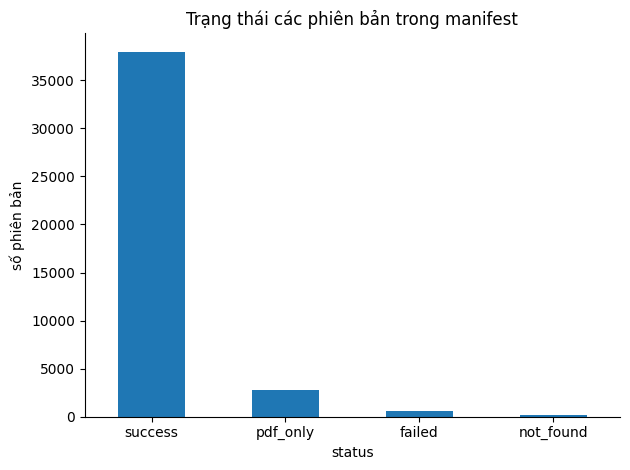

In [12]:
cov, ver_summary = None, None
mf_files = sorted(DATA.glob("versions_manifest*.jsonl"))
if not mf_files:
    print("Chưa có versions_manifest*.jsonl trong", DATA.resolve(), "-> bỏ qua độ phủ phiên bản.")
else:
    mf = pd.concat([pd.read_json(f, lines=True, dtype={"arxiv_id": str}) for f in mf_files], ignore_index=True)
    mf["arxiv_id"] = mf["arxiv_id"].map(normalize_arxiv_id)
    mf["version"] = mf["version"].astype(str).str.lstrip("v").astype(int)
    mf = mf.drop_duplicates(["arxiv_id", "version"], keep="last")
    mf = mf[mf["arxiv_id"].isin(meta["arxiv_id"])]
    resolved = mf[mf["status"].isin(["success", "pdf_only", "not_found"])].groupby("arxiv_id").size().rename("v_resolved")
    content  = mf[mf["status"].isin(["success", "pdf_only"])].groupby("arxiv_id").size().rename("v_content")
    cov = (meta[["arxiv_id", "id_range", "num_versions"]]
           .merge(resolved, on="arxiv_id", how="left").merge(content, on="arxiv_id", how="left").fillna(0))
    cov["in_manifest"] = cov.arxiv_id.isin(mf.arxiv_id)
    cov["cov_content"] = cov.v_content / cov.num_versions
    have = cov[cov.in_manifest]
    ver_summary = {
        "papers_in_manifest": int(len(have)), "papers_total": int(len(cov)),
        "versions_discovered": int(have.num_versions.sum()), "versions_in_manifest": int(len(mf)),
        "coverage_resolved": round(float(have.v_resolved.sum() / have.num_versions.sum()), 4),
        "coverage_content": round(float(have.v_content.sum() / have.num_versions.sum()), 4),
        "papers_fully_covered": round(float((have.cov_content == 1).mean()), 4),
    }
    print(ver_summary)
    print(mf["status"].value_counts().to_dict())
    mf["status"].value_counts().plot.bar(rot=0, title="Trạng thái các phiên bản trong manifest", ylabel="số phiên bản")
    save("11_version_status")

## 12. Xuất file tóm tắt.

In [13]:
from datetime import datetime, timezone
if not (disc.arxiv_id.is_unique and dl.arxiv_id.is_unique and ref.arxiv_id.is_unique):
    raise ValueError("Không thể xuất m1_summary.json: arxiv_id bị trùng trong input.")
if set(disc.arxiv_id) != set(dl.arxiv_id):
    raise ValueError("Không thể xuất m1_summary.json: discovery và download lệch tập ID.")
if not set(ref.arxiv_id).issubset(set(disc.arxiv_id)):
    raise ValueError("Không thể xuất m1_summary.json: reference có ID ngoài discovery.")
manifest_available = bool(mf_files) and "mf" in globals() and "status" in mf.columns and not mf.empty
status_counts = mf["status"].value_counts().to_dict() if manifest_available else {}
expected_versions = int(meta["num_versions"].sum())
verified_source_versions = int(status_counts.get("success", 0))
source_statuses = None
if manifest_available:
    source_statuses = {
        "verified_success": verified_source_versions,
        "verified_pdf_only": int(status_counts.get("pdf_only", 0)),
        "pending": int(status_counts.get("pending", 0)),
        "failed": int(status_counts.get("failed", 0)),
        "not_found": int(status_counts.get("not_found", 0)),
        "conflicts": int(status_counts.get("conflict", 0) + status_counts.get("conflicts", 0)),
        "missing_files": int(status_counts.get("missing_files", 0)),
    }
missing_evidence = []
if not manifest_available:
    missing_evidence.append("Không có versions_manifest; chưa thể xác nhận trạng thái từng version.")
elif len(mf) < expected_versions:
    missing_evidence.append(
        f"Manifest có {len(mf):,}/{expected_versions:,} dòng version dự kiến."
    )
missing_evidence.append("Raw archive nén và .tex/.bib đã giải nén không phải phép đo trực tiếp trước/sau loại hình.")
source_file_statistics = {
    "mean_raw_compressed_archive_bytes_tex_papers": summary["avg_raw_bytes_tex"],
    "median_raw_compressed_archive_bytes_tex_papers": summary["median_raw_bytes_tex"],
    "mean_extracted_tex_bib_bytes_tex_papers": summary["avg_cleaned_bytes_tex"],
    "median_extracted_tex_bib_bytes_tex_papers": summary["median_cleaned_bytes_tex"],
    "interpretation_note": "Archive nén và .tex/.bib đã giải nén; không diễn giải là dung lượng trước/sau xóa hình.",
}
official_bench = None
if "bench" in globals() and not bench.empty:
    t_sec = float(bench.total_wall_time_sec.sum())
    p_cnt = float(bench.total_papers.sum())
    per_member_dict = {}
    for name, g in bench.groupby("member"):
        t_sub = g["total_wall_time_sec"]
        per_member_dict[name] = {
            "batches": int(len(g)),
            "papers": int(g["total_papers"].sum()),
            "wall_time_hours": round(float(t_sub.sum() / 3600), 2),
            "sec_per_paper": round(float(t_sub.sum() / g["total_papers"].sum()), 2),
            "peak_ram_mb": round(float(g["peak_ram_mb"].max()), 2),
            "avg_ram_mb": round(float((g["average_ram_mb"] * t_sub).sum() / t_sub.sum()), 2),
            "peak_disk_mb": round(float(g["peak_disk_mb"].max()), 2),
            "final_storage_mb": round(float(g["final_storage_mb"].iloc[-1]), 2),
        }
    official_bench = {
        "testbed": "Google Colab CPU-only",
        "total_papers": int(p_cnt),
        "total_wall_time_sec": round(t_sec, 2),
        "total_wall_time_hours": round(t_sec / 3600, 2),
        "avg_sec_per_paper": round(t_sec / p_cnt, 2),
        "discovery_total_hours": round(float(meta.discovery_time_sec.sum() / 3600), 2),
        "discovery_avg_sec_per_paper": round(float(meta.discovery_time_sec.mean()), 4),
        "download_total_hours": round(float(meta.download_time_sec.sum() / 3600), 2),
        "download_avg_sec_per_paper": round(float(meta.download_time_sec.mean()), 2),
        "reference_total_hours": round(float(meta.ref_time_sec.sum() / 3600), 2),
        "reference_avg_sec_per_paper": round(float(meta.ref_time_sec.mean()), 4),
        "peak_ram_mb": round(float(bench.peak_ram_mb.max()), 2),
        "weighted_avg_ram_mb": round(float((bench.average_ram_mb * bench.total_wall_time_sec).sum() / t_sec), 2),
        "peak_disk_mb": round(float(bench.peak_disk_mb.max()), 2),
        "final_storage_mb": round(float(bench.groupby("member")["final_storage_mb"].last().sum()), 2),
        "per_member": per_member_dict,
    }
dl_range_pct = (st.div(st.sum(axis=1), axis=0) * 100).round(2)
v_dist = meta.num_versions.value_counts().sort_index()
bench_batches_data = []
if "bench" in globals() and not bench.empty:
    for _, r in bench.iterrows():
        bench_batches_data.append({
            "member": r["member"],
            "batch": int(r["batch"]),
            "sec_per_paper": round(float(r["sec_per_paper"]), 2),
            "peak_ram_mb": round(float(r["peak_ram_mb"]), 2),
            "final_storage_mb": round(float(r["final_storage_mb"]), 2),
        })

rc = meta.num_crawled_refs.dropna()
q_rc = float(rc.quantile(0.99))
rc_c = np.clip(rc, 0, q_rc)
rc_counts, rc_edges = np.histogram(rc_c, bins=40)

ra = meta.num_arxiv_refs.dropna()
q_ra = float(ra.quantile(0.99))
ra_c = np.clip(ra, 0, q_ra)
ra_counts, ra_edges = np.histogram(ra_c, bins=40)

tex_mask = meta.download_status == "success"
raw_s = meta.loc[tex_mask & (meta.raw_size_bytes > 0), "raw_size_bytes"]
clean_s = meta.loc[tex_mask & (meta.cleaned_size_bytes > 0), "cleaned_size_bytes"]
min_b = max(1.0, float(min(raw_s.min(), clean_s.min())))
max_b = float(max(raw_s.quantile(0.99), clean_s.quantile(0.99)))
size_bins = np.logspace(np.log10(min_b), np.log10(max_b), 40)
raw_counts, _ = np.histogram(raw_s, bins=size_bins)
clean_counts, _ = np.histogram(clean_s, bins=size_bins)

bench_pivots = {}
if "bench" in globals() and not bench.empty:
    for col in ["sec_per_paper", "peak_ram_mb", "final_storage_mb"]:
        bench_pivots[col] = bench.pivot(index="batch", columns="member", values=col).to_dict()

hist_data = {
    "refs": {
        "crawled_counts": [int(x) for x in rc_counts],
        "crawled_edges": [float(x) for x in rc_edges],
        "arxiv_counts": [int(x) for x in ra_counts],
        "arxiv_edges": [float(x) for x in ra_edges],
    },
    "sizes": {
        "bins": [float(x) for x in size_bins],
        "raw_counts": [int(x) for x in raw_counts],
        "cleaned_counts": [int(x) for x in clean_counts],
    },
    "bench_pivots": bench_pivots,
}

report_summary = {
    "schema_version": 1,
    "generated_at": datetime.now(timezone.utc).isoformat(),
    "integrity_status": "eda_table_checks_passed" if manifest_available else "version_manifest_missing",
    "coverage": {
        "valid_metadata_papers": int((meta["discovery_status"] == "success").sum()),
        "expected_versions": expected_versions,
        "verified_source_versions": verified_source_versions if manifest_available else None,
        "source_coverage_pct": round(100 * verified_source_versions / expected_versions, 2)
            if manifest_available and expected_versions else None,
        "raw_reference_papers_verified": int((meta["ref_status"] == "success").sum()),
    },
    "source_statuses": source_statuses,
    "source_file_statistics": source_file_statistics,
    "benchmark_evidence": {
        "official_version_pipeline_metrics": official_bench,
        "legacy_run_count": int(len(bench)) if "bench" in globals() else 0,
    },
    "missing_evidence": missing_evidence,
    "eda_metrics": summary,
    "version_coverage": ver_summary,
    "download_status_by_range": dl_range_pct.to_dict(orient="index"),
    "version_distribution": {str(k): int(v) for k, v in v_dist.items()},
    "category_top15": top.to_dict() if "top" in globals() else {},
    "category_vs_quality_top10": tab.to_dict(orient="index") if "tab" in globals() else {},
    "benchmark_batches": bench_batches_data,
    "hist_data": hist_data,
}

(OUT / "m1_eda_summary.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8"
)
report_summary_path = OUT / "m1_summary.json"
report_summary_path.write_text(
    json.dumps(report_summary, ensure_ascii=False, indent=2), encoding="utf-8"
)

book_data_dir = Path("../book/_data") if Path("../book").exists() else Path("book/_data")
book_data_dir.mkdir(parents=True, exist_ok=True)
(book_data_dir / "m1_summary.json").write_text(
    json.dumps(report_summary, ensure_ascii=False, indent=2), encoding="utf-8"
)

dl_range_pct.to_csv(OUT / "download_status_by_range.csv")
v_dist.rename_axis("num_versions").rename("papers").reset_index().to_csv(OUT / "version_distribution.csv", index=False)
meta.groupby("ver_group").agg(papers=("arxiv_id", "count"), pdf_only_rate=("download_status", lambda s: (s == "pdf_only").mean()),
                              mean_refs_successful=("num_crawled_refs_valid", "mean")).round(4).to_csv(OUT / "versions_vs_quality.csv")
if "bench" in globals():
    bench.round(3).to_csv(OUT / "benchmark_summary.csv", index=False)
if "per_member" in globals():
    per_member.to_csv(OUT / "benchmark_per_member.csv")
if ver_summary is not None:
    (OUT / "m1_version_coverage_summary.json").write_text(
        json.dumps(ver_summary, ensure_ascii=False, indent=2), encoding="utf-8"
    )
for csv_file in OUT.glob("*.csv"):
    (book_data_dir / csv_file.name).write_text(csv_file.read_text(encoding="utf-8"), encoding="utf-8")
print("Đã xuất:", OUT / "m1_eda_summary.json")
print("Book summary:", report_summary_path.resolve())
print("Book _data summary:", (book_data_dir / "m1_summary.json").resolve())
print(sorted(p.name for p in OUT.iterdir() if p.is_file()))

Đã xuất: data\eda_output\m1_eda_summary.json
Book summary: D:\HCMUS_N3\arXiv\arXiv-Project\notebooks\data\eda_output\m1_summary.json
Book _data summary: D:\HCMUS_N3\arXiv\arXiv-Project\notebooks\book\_data\m1_summary.json
['benchmark_per_member.csv', 'benchmark_summary.csv', 'category_top15.csv', 'category_vs_quality_top10.csv', 'download_status_by_range.csv', 'm1_eda_summary.json', 'm1_summary.json', 'm1_version_coverage_summary.json', 'version_distribution.csv', 'versions_vs_quality.csv']
